In [13]:
import proteosim_max as ps
proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)

3

In [4]:
peptides = ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns["Trypsin"])
sample_protein = proteins["P11802"]
sample_protein_peptides = peptides["P11802"]
sample_coverage = ps.compute_sequence_coverage(sample_protein, sample_protein_peptides)
sample_coverage

92.73927392739274

In [ ]:
ps.digest_protein_sequence(sample_protein, ps.enzyme_cleavage_patterns['LysC'])


{'P11802': ['MATSRYEPVAEIGVGAYGTVYK',
  'ARDPHSGHFVALK',
  'VTLVFEHVDQDLRTYLDK',
  'APPPGLPAETIK',
  'DLMRQFLRGLDFLHANCIVHRDLK',
  'PENILVTSGGTVK',
  'PLFCGNSEADQLGK',
  'RISAFRALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK'],
 'A0A087WTH5': ['MVIEWERPRMILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLARRSPRSGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIRSK',
  'LEHSNDPFNVYIESNAWQEK']}

In [29]:
ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns['LysC'])


{'P11802': ['MATSRYEPVAEIGVGAYGTVYK',
  'ARDPHSGHFVALK',
  'VTLVFEHVDQDLRTYLDK',
  'APPPGLPAETIK',
  'DLMRQFLRGLDFLHANCIVHRDLK',
  'PENILVTSGGTVK',
  'PLFCGNSEADQLGK',
  'RISAFRALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK'],
 'A0A087WTH5': ['MVIEWERPRMILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLARRSPRSGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIRSK',
  'LEHSNDPFNVYIESNAWQEK']}

In [31]:
digested_peptides_map = ps.digest_protein_collection(proteins, ps.enzyme_cleavage_patterns["Trypsin"])

In [22]:
ps.compute_sequence_coverage(proteins["P11802"],digested_peptides_map["P11802"])

92.73927392739274

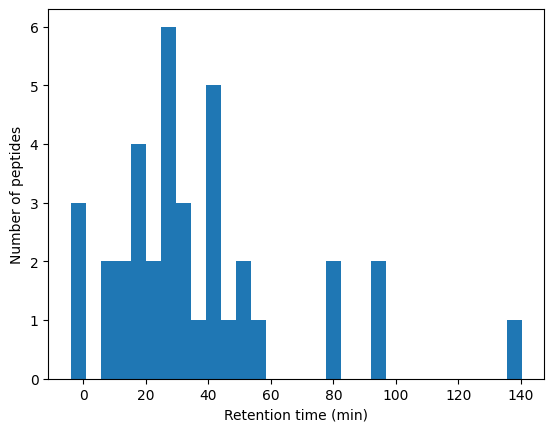

['AYVQAR', 'VLESYR', 'GAFPPR', 'SEEAVR', 'TYLDK', 'ISAFR', 'DVSLPR', 'MATSR']

In [23]:

pooled_peptides = list(set().union(*digested_peptides_map.values()))


ps.predict_lc_retention_times(pooled_peptides)
ps.plot_retention_time(ps.predict_lc_retention_times(pooled_peptides).values(), resolution=30)
ps.select_retention_time_window(ps.predict_lc_retention_times(pooled_peptides), lower_ret_time=0, upper_ret_time=20)

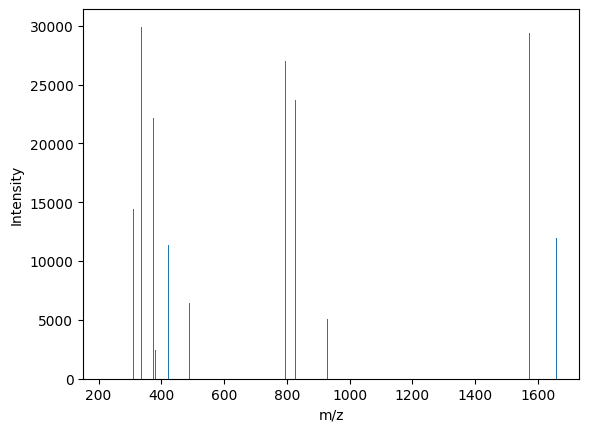

In [ ]:
ps.calculate_mol_mass(proteins["P11802"], ps.amino_acid_mass_dalton)
ps.calculate_mol_mass_collection(pooled_peptides, ps.amino_acid_mass_dalton)

mass_peptide_map = ps.calculate_mol_mass_collection(pooled_peptides, ps.amino_acid_mass_dalton)
mz_values = ps.calculate_mz_collection(mass_peptide_map, charge = 2)
ps.plot_spectrum(mz_values)

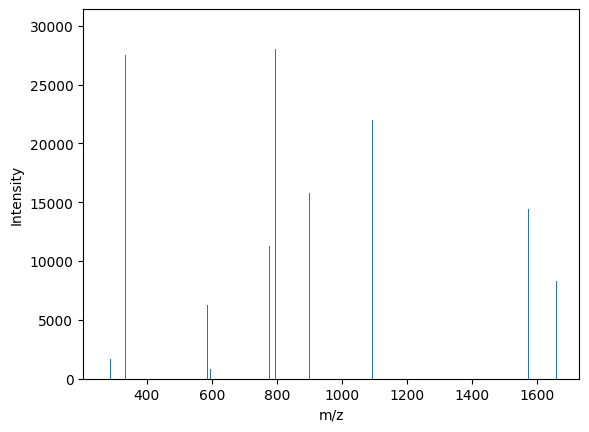

['M', 'MA', 'MAT', 'MATS', 'R', 'SR', 'TSR', 'ATSR']

In [35]:
mol_mass_collection = ps.calculate_mol_mass_collection(sample_protein_peptides, ps.amino_acid_mass_dalton)
mz_collection = ps.calculate_mz_collection(mol_mass_collection, charge=2)

ps.plot_spectrum(mz_collection)

sample_peptide = "MATSR"
fragments = ps.fragment_peptide(sample_peptide)
fragments

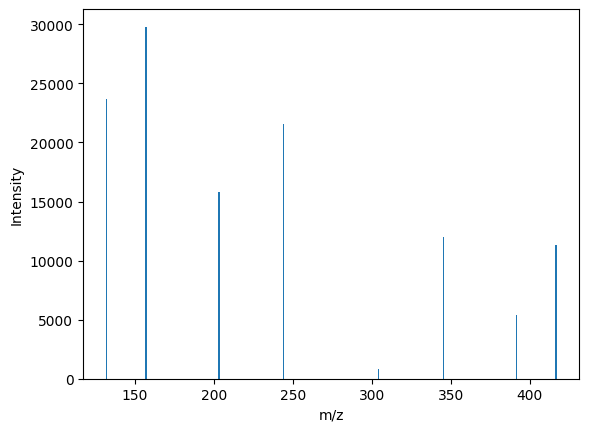

In [38]:
fragment_masses_ms2 = ps.calculate_mol_mass_collection(fragments, ps.amino_acid_mass_dalton)
fragment_mz2_collection = ps.calculate_mz_collection(fragment_masses_ms2, 1)

ps.plot_spectrum(fragment_mz2_collection)